## 1. Setup and locate the shared repository

In [11]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from repository root or a nested notebooks/ directory.
root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in root_candidates if (p / "split_config.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "split_config.py was not found in the current folder or its parents. "
        "Place the TEAM'S shared split_config.py in the repository root, "
        "open this notebook inside that repository, and rerun. "
        "Do not recreate the shared configuration."
    )
sys.path.insert(0, str(ROOT))
from split_config import (
    DATA_PATH, TRAIN_LOCAL_START, VAL_LOCAL_START, TEST_LOCAL_START,
    SAFE_LAGS_HOURS, FORECAST_COVERAGE_VERIFIED,
    load_data, split, local_midnight,
    seasonal_naive, seasonal_average_prediction,
    check_predictions, validation_index, metrics,
)
OUT = ROOT / "predictions"
FIG = OUT / "task1_figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Required shared dataset missing: {DATA_PATH}")

## 2. Load and verify the official chronological split

In [12]:
df = load_data()
train, val = split(df)  # The 2025 test is not returned.
assert isinstance(df.index, pd.DatetimeIndex) and df.index.tz is not None, "Expected timezone-aware index"
assert str(df.index.tz) in ("UTC", "datetime.timezone.utc"), "Expected UTC index from shared loader"
assert df.index.is_unique and df.index.is_monotonic_increasing
assert train.index.is_unique and val.index.is_unique
assert train.index.intersection(val.index).empty
assert len(val) == 8784, "2024 validation should have 8784 hourly rows"
assert (val.index.tz_convert("Europe/Rome").year == 2024).all()
assert (train.index.tz_convert("Europe/Rome").year <= 2023).all()
assert {"actual_load_mw", "terna_forecast_mw"}.issubset(df.columns)
print("Train starts:", TRAIN_LOCAL_START, "| rows:", len(train))
print("Validation starts:", VAL_LOCAL_START, "| rows:", len(val))
print("Test begins (not loaded):", TEST_LOCAL_START)
print("Safe lags (not needed for Task 1):", SAFE_LAGS_HOURS)
print("Forecast weather verified (not needed):", FORECAST_COVERAGE_VERIFIED)
print("Validation local-day lengths:", local_midnight(val.index).value_counts().value_counts().sort_index().to_dict())
display(val[["actual_load_mw", "terna_forecast_mw"]].head())

Train starts: 2022-01-16 | rows: 17160
Validation starts: 2024-01-01 | rows: 8784
Test begins (not loaded): 2025-01-01
Safe lags (not needed for Task 1): (48, 168, 336)
Forecast weather verified (not needed): False
Validation local-day lengths: {23: 1, 24: 364, 25: 1}


,actual_load_mw,terna_forecast_mw
timestamp,,
2023-12-31 23:00:00+00:00,20694.0,20725.0
2024-01-01 00:00:00+00:00,19910.0,20053.0
2024-01-01 01:00:00+00:00,18833.0,18851.0
2024-01-01 02:00:00+00:00,17878.0,17792.0
2024-01-01 03:00:00+00:00,17312.0,17677.0


## 3. Generate the three baselines (shared implementations)


In [13]:
y_true = val["actual_load_mw"].copy()
naive = seasonal_naive(df).loc[val.index]
avg = seasonal_average_prediction(train, val)
terna = val["terna_forecast_mw"].copy()

def as_aligned_series(values, name):
    if not isinstance(values, pd.Series):
        raise TypeError(f"{name}: expected a pandas Series from the shared helper")
    if not values.index.equals(val.index):
        raise ValueError(f"{name}: prediction index must equal validation index")
    return pd.to_numeric(values, errors="raise")

naive = as_aligned_series(naive, "seasonal_naive")
avg = as_aligned_series(avg, "seasonal_avg")
terna = as_aligned_series(terna, "terna")
assert y_true.notna().all() and np.isfinite(y_true).all()
assert avg.notna().all() and np.isfinite(avg).all()
assert terna.notna().all() and np.isfinite(terna).all()
missing_naive = naive[naive.isna()].index
expected_missing = pd.Timestamp("2024-04-07 00:00:00", tz="UTC")  # 02:00 CEST
assert len(missing_naive) == 1 and missing_naive[0] == expected_missing, (
    "Unexpected seasonal naive missing hour(s): " + str(list(missing_naive))
)
assert np.isfinite(naive.dropna()).all()
print("Seasonal naive omitted UTC hour:", missing_naive[0], "(2024-04-07 02:00 Europe/Rome)")
print("Seasonal naive n:", naive.notna().sum())
print("Seasonal average n:", avg.notna().sum())
print("Terna n:", terna.notna().sum())

Seasonal naive omitted UTC hour: 2024-04-07 00:00:00+00:00 (2024-04-07 02:00 Europe/Rome)
Seasonal naive n: 8783
Seasonal average n: 8784
Terna n: 8784


## 4. Export exact prediction files and validate them


In [15]:
predictions = {
    "seasonal_naive": naive,
    "seasonal_avg": avg,
    "terna": terna,
}
validated = {}
for model_name, pred in predictions.items():
    valid_mask = pred.notna()
    result = pd.DataFrame({
        "timestamp": val.index[valid_mask].strftime("%Y-%m-%dT%H:%M:%SZ"),
        "y_true": y_true.loc[valid_mask].to_numpy(),
        "y_pred": pred.loc[valid_mask].to_numpy(),
        "model": model_name,
    })
    assert list(result.columns) == ["timestamp", "y_true", "y_pred", "model"]
    assert result["timestamp"].is_unique
    assert np.isfinite(result["y_pred"]).all()
    csv_path = OUT / f"{model_name}.csv"
    result.to_csv(csv_path, index=False)
    validated[model_name] = check_predictions(
        csv_path, validation_index(df), reference_y=df["actual_load_mw"]
    )

## 5. Validation MAE, RMSE, and sample size


In [6]:
summary_rows = []
for model_name, pred in predictions.items():
    mask = pred.notna()
    actual = y_true.loc[mask]
    predicted = pred.loc[mask]
    # Explicit formulas for stable numeric output; shared metrics are printed as a cross-check.
    error = actual.to_numpy() - predicted.to_numpy()
    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(np.square(error))))
    summary_rows.append({"model": model_name, "n": int(mask.sum()),
                         "MAE_MW": mae, "RMSE_MW": rmse})
    print(model_name, "shared metrics:", metrics(actual, predicted))
summary = pd.DataFrame(summary_rows).set_index("model")
display(summary.round(2))
summary.to_csv(OUT / "task1_validation_metrics.csv")

seasonal_naive shared metrics: {'n': 8783, 'MAE': 1975.1383354206991, 'RMSE': 3177.1857545852185}
seasonal_avg shared metrics: {'n': 8784, 'MAE': 2718.4583601525123, 'RMSE': 3653.9114403215176}
terna shared metrics: {'n': 8784, 'MAE': 603.9311247723133, 'RMSE': 816.2995993265314}


,n,MAE_MW,RMSE_MW
model,,,
seasonal_naive,8783,1975.14,3177.19
seasonal_avg,8784,2718.46,3653.91
terna,8784,603.93,816.30


## 6. Plots — representative week and Ferragosto


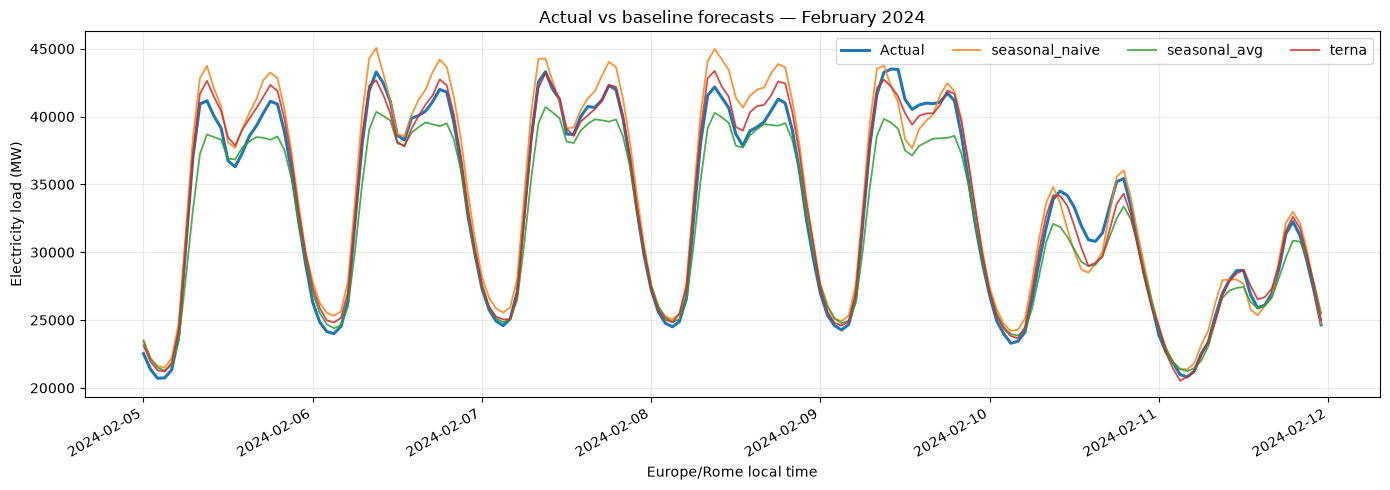

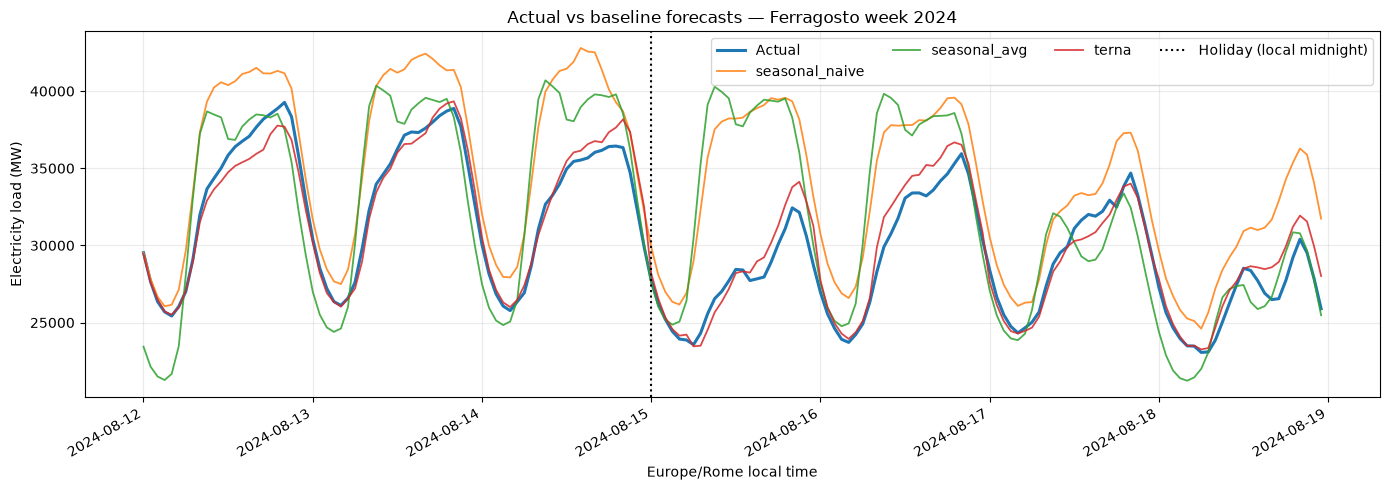

In [16]:
comparison = pd.DataFrame({
    "actual": y_true, "seasonal_naive": naive,
    "seasonal_avg": avg, "terna": terna,
})

def plot_local_period(start_date, end_date, title, filename, holiday_date=None):
    local_index = comparison.index.tz_convert("Europe/Rome")
    start = pd.Timestamp(start_date, tz="Europe/Rome")
    end_exclusive = pd.Timestamp(end_date, tz="Europe/Rome") + pd.Timedelta(days=1)
    period = comparison.loc[(local_index >= start) & (local_index < end_exclusive)]
    assert len(period) > 0, f"No validation rows in {title}"
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(period.index.tz_convert("Europe/Rome"), period["actual"], label="Actual", lw=2.2)
    for name in predictions:
        ax.plot(period.index.tz_convert("Europe/Rome"), period[name], label=name, lw=1.3, alpha=0.85)
    if holiday_date is not None:
        ax.axvline(pd.Timestamp(holiday_date, tz="Europe/Rome"),
                   linestyle=":", color="black", label="Holiday (local midnight)")
    ax.set(title=title, xlabel="Europe/Rome local time", ylabel="Electricity load (MW)")
    ax.legend(ncol=4)
    ax.grid(alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(FIG / filename, dpi=160)
    plt.show()

plot_local_period("2024-02-05", "2024-02-11",
                  "Actual vs baseline forecasts — February 2024", "february_week.png")
plot_local_period("2024-08-12", "2024-08-18",
                  "Actual vs baseline forecasts — Ferragosto week 2024",
                  "ferragosto_week.png", holiday_date="2024-08-15")

## 7. Error patterns by local hour and holiday status

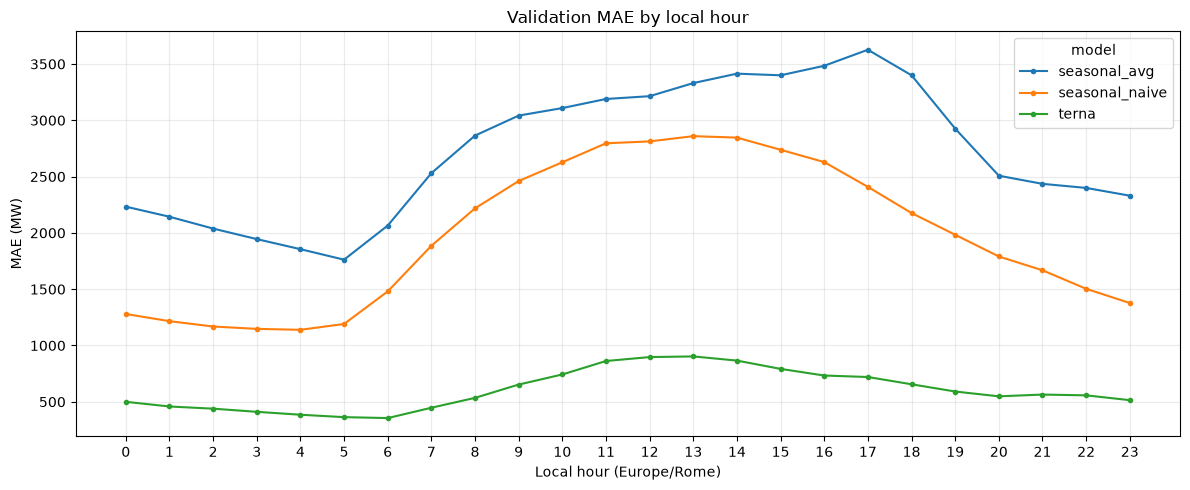

Error by SHARED holiday flag (not a newly computed civil-holiday flag):


mean  count
model          is_holiday                
seasonal_avg   0           2531.41   8497
               1           8256.40    287
seasonal_naive 0           1835.29   8496
               1           6115.14    287
terna          0            599.52   8497
               1            734.66    287

,model,period,n,MAE_MW,mean_signed_error_MW
0,seasonal_naive,Ferragosto week,168,4045.84,-4045.77
1,seasonal_naive,Other validation hours,8615,1934.76,97.84
2,seasonal_avg,Ferragosto week,168,3241.60,-1780.25
3,seasonal_avg,Other validation hours,8616,2708.26,-327.57
4,terna,Ferragosto week,168,769.50,-263.30
5,terna,Other validation hours,8616,600.70,-195.51


In [8]:
local_idx = comparison.index.tz_convert("Europe/Rome")
error_long = []
for name in predictions:
    e = (comparison["actual"] - comparison[name]).abs()
    part = pd.DataFrame({
        "model": name, "absolute_error_mw": e.to_numpy(),
        "local_hour": local_idx.hour,
        "local_date": local_idx.date,
    }, index=comparison.index)
    if "is_holiday" in val.columns:
        part["is_holiday"] = val["is_holiday"].to_numpy()
    error_long.append(part)
error_long = pd.concat(error_long).dropna(subset=["absolute_error_mw"])
hourly = error_long.groupby(["model", "local_hour"])["absolute_error_mw"].mean().unstack(0)
ax = hourly.plot(figsize=(12, 5), marker="o", markersize=3)
ax.set(title="Validation MAE by local hour", xlabel="Local hour (Europe/Rome)", ylabel="MAE (MW)")
ax.set_xticks(range(24))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIG / "mae_by_local_hour.png", dpi=160)
plt.show()

if "is_holiday" in val.columns:
    holiday_table = error_long.groupby(["model", "is_holiday"])["absolute_error_mw"].agg(["mean", "count"])
    print("Error by SHARED holiday flag (not a newly computed civil-holiday flag):")
    display(holiday_table.round(2))
else:
    print("WARNING: is_holiday missing from shared data; holiday-flag analysis skipped.")

ferragosto_mask = ((local_idx >= pd.Timestamp("2024-08-12", tz="Europe/Rome")) &
                   (local_idx < pd.Timestamp("2024-08-19", tz="Europe/Rome")))
period_summary = []
for name, pred in predictions.items():
    for period_name, mask in [("Ferragosto week", ferragosto_mask),
                              ("Other validation hours", ~ferragosto_mask)]:
        e = (y_true[mask] - pred[mask]).dropna()
        period_summary.append({"model": name, "period": period_name,
                               "n": len(e), "MAE_MW": e.abs().mean(),
                               "mean_signed_error_MW": e.mean()})
period_table = pd.DataFrame(period_summary)
display(period_table.round(2))

## 8. Baseline MAE/RMSE comparison

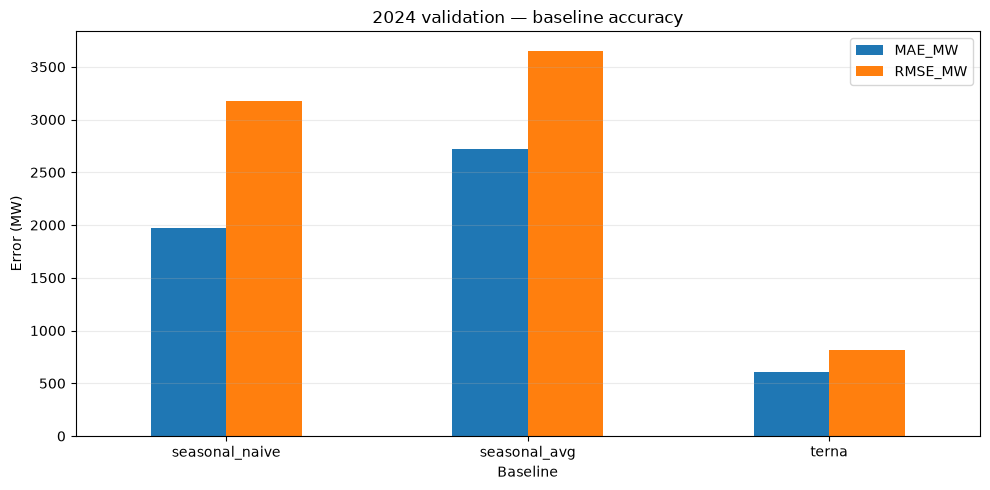

In [9]:
ax = summary[["MAE_MW", "RMSE_MW"]].plot(kind="bar", figsize=(10, 5), rot=0)
ax.set(title="2024 validation — baseline accuracy", ylabel="Error (MW)", xlabel="Baseline")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIG / "model_metrics.png", dpi=160)
plt.show()

## 9. One-line failure comments (data-driven)


In [10]:
comments = {}
for name in predictions:
    row = period_table[period_table["model"] == name].set_index("period")
    ferr = row.loc["Ferragosto week"]
    other = row.loc["Other validation hours"]
    direction = ("underpredicted" if ferr["mean_signed_error_MW"] > 0 else
                 "overpredicted" if ferr["mean_signed_error_MW"] < 0 else "had zero mean bias")
    comparison_word = "higher" if ferr["MAE_MW"] > other["MAE_MW"] else "lower or equal"
    comments[name] = (
        f"{name}: Ferragosto-week MAE was {ferr['MAE_MW']:.1f} MW "
        f"({comparison_word} than {other['MAE_MW']:.1f} MW outside that week); "
        f"on average it {direction} load during Ferragosto week."
    )
for line in comments.values():
    print("-", line)
(OUT / "task1_failure_comments.txt").write_text("\n".join(comments.values()) + "\n", encoding="utf-8")
print("\nSeasonal naive exception: omitted 2024-04-07 00:00:00Z (02:00 Europe/Rome); n=8783.")
print("2025 test was not evaluated.")

- seasonal_naive: Ferragosto-week MAE was 4045.8 MW (higher than 1934.8 MW outside that week); on average it overpredicted load during Ferragosto week.
- seasonal_avg: Ferragosto-week MAE was 3241.6 MW (higher than 2708.3 MW outside that week); on average it overpredicted load during Ferragosto week.
- terna: Ferragosto-week MAE was 769.5 MW (higher than 600.7 MW outside that week); on average it overpredicted load during Ferragosto week.

Seasonal naive exception: omitted 2024-04-07 00:00:00Z (02:00 Europe/Rome); n=8783.
2025 test was not evaluated.
